# Label log: first look

A quick check that the label log makes sense. Each row is one label created during pricing:
its state when it was created (features) and what happened to it later (outcome).

Outcomes:
- **rejected at insertion**: dominated by a label already in its bucket, never stored
- **removed later**: stored, then removed by a newer label that dominates it
- **alive at end**: still stored when the pricing call ended

In [8]:
import ast
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Load

`LOG_DIR` defaults to the newest run in `output/label_logs/`. Set it to a specific folder to look at another run.

In [9]:
LOG_ROOT = Path("../output/label_logs")
LOG_DIR = sorted(p for p in LOG_ROOT.iterdir() if (p / "layout.txt").exists())[-1]
print(LOG_DIR)


def load_label_log(log_dir):
    """Return (labels, calls): one row per label, one row per pricing call."""
    log_dir = Path(log_dir)
    dtypes = {}
    for line in (log_dir / "layout.txt").read_text().splitlines():
        if line.startswith(("feature_dtype", "outcome_dtype")):
            key, value = line.split(" = ", 1)
            dtypes[key] = np.dtype(ast.literal_eval(value))
    feat = np.concatenate([np.fromfile(p, dtype=dtypes["feature_dtype"])
                           for p in sorted(log_dir.glob("features_*.bin"))])
    outc = np.concatenate([np.fromfile(p, dtype=dtypes["outcome_dtype"])
                           for p in sorted(log_dir.glob("outcomes_*.bin"))])
    columns = {}
    for name in feat.dtype.names:
        if feat[name].ndim == 1:
            columns[name] = feat[name]
        else:  # res has one column per resource
            for k in range(feat[name].shape[1]):
                columns[f"{name}_{k}"] = feat[name][:, k]
    labels = pd.DataFrame(columns).merge(pd.DataFrame(outc), on="label_id", validate="one_to_one")
    calls = pd.read_csv(log_dir / "calls.csv")
    return labels, calls


labels, calls = load_label_log(LOG_DIR)

OUTCOME_NAMES = {0: "rejected at insertion", 1: "removed later", 2: "alive at end", 3: "discarded by restart"}
labels["outcome_name"] = labels["outcome"].map(OUTCOME_NAMES)
labels = labels.merge(calls[["call_id", "level", "cg_iter"]], on="call_id")
print(f"{len(labels):,} labels in {len(calls)} pricing calls")
labels.head()

../output/label_logs/P-n20-k2_20261103_110358
177,541 labels in 72 pricing calls


,label_id,pred_id,call_id,vertex,pred_vertex,bucket,dir,attempt,arc_kind,rc,...,bucket_stored,bucket_open,bucket_closed,dominator_id,skip_dominator_id,outcome,ext_state,outcome_name,level,cg_iter
0,0,18446744073709551615,0,1,0,1,1,0,0,0.0,...,0,0,0,18446744073709551615,18446744073709551615,2,1,alive at end,light,1
1,1,18446744073709551615,0,2,0,2,1,0,0,0.0,...,0,0,0,18446744073709551615,18446744073709551615,2,1,alive at end,light,1
2,2,18446744073709551615,0,3,0,1,1,0,0,0.0,...,0,0,0,18446744073709551615,18446744073709551615,2,1,alive at end,light,1
3,3,18446744073709551615,0,4,0,1,1,0,0,0.0,...,0,0,0,18446744073709551615,18446744073709551615,2,1,alive at end,light,1
4,4,18446744073709551615,0,5,0,0,1,0,0,0.0,...,0,0,0,18446744073709551615,18446744073709551615,2,1,alive at end,light,1


## Sanity checks

Every label should have exactly one outcome, and the per-call counts should match `calls.csv`.

In [10]:
assert labels["label_id"].is_unique
assert (calls["n_features"] == calls["n_outcomes"]).all()
per_call = labels.groupby("call_id").size()
assert (per_call.reindex(calls["call_id"], fill_value=0).values == calls["n_features"].values).all()
print("checks passed")

labels["outcome_name"].value_counts()

checks passed


outcome_name
rejected at insertion    105975
alive at end              42434
removed later             29132
Name: count, dtype: int64

In [11]:
# Fixed colors per outcome, so every plot uses the same color for the same outcome.
COLORS = {"rejected at insertion": "#eb6834", "removed later": "#eda100",
          "alive at end": "#2a78d6", "discarded by restart": "#52514e"}
outcomes = [name for name in OUTCOME_NAMES.values() if name in set(labels["outcome_name"])]

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False,
})

## 1. Labels per pricing call

How many labels each call creates, split by outcome. Calls are in the order they ran.

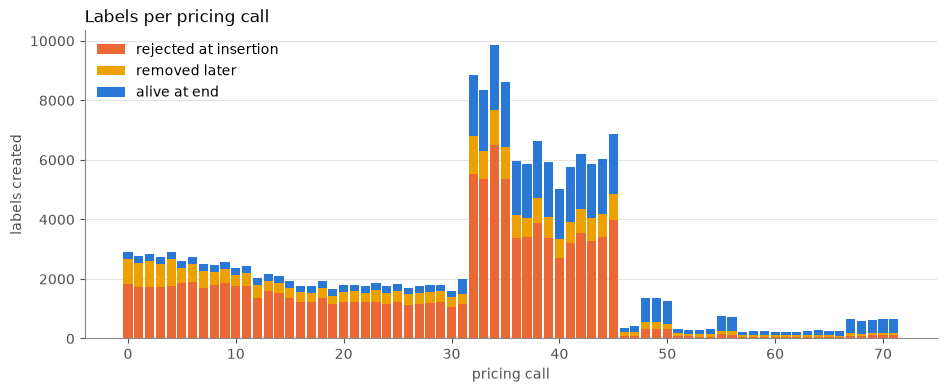

In [12]:
counts = labels.pivot_table(index="call_id", columns="outcome_name", values="label_id",
                            aggfunc="size", fill_value=0)[outcomes]

fig, ax = plt.subplots(figsize=(11, 4))
bottom = np.zeros(len(counts))
for name in outcomes:
    ax.bar(counts.index, counts[name], bottom=bottom, width=0.85, color=COLORS[name], label=name)
    bottom += counts[name].values
ax.set_xlabel("pricing call")
ax.set_ylabel("labels created")
ax.set_title("Labels per pricing call", loc="left")
ax.legend(loc="upper left")
plt.show()

## 2. Outcome share by pricing level

LIGHT and HEAVY are the heuristic levels (fewer dominance rules), EXACT is the full labeling.

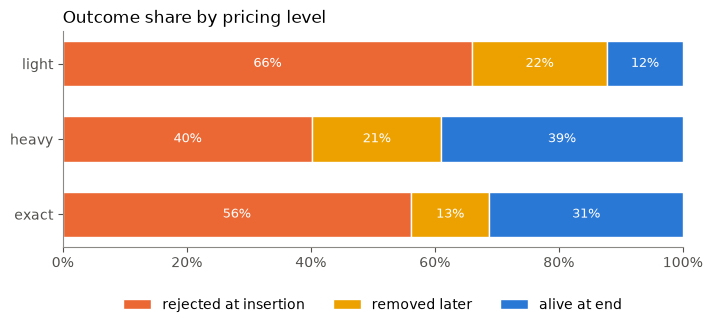

outcome_name,rejected at insertion,removed later,alive at end
level,,,
light,0.660,0.218,0.122
heavy,0.403,0.207,0.390
exact,0.561,0.127,0.312


In [13]:
share = (labels.groupby("level")["outcome_name"].value_counts(normalize=True)
         .unstack(fill_value=0)[outcomes]
         .reindex([lv for lv in ["light", "heavy", "exact"] if lv in set(labels["level"])]))

fig, ax = plt.subplots(figsize=(8, 2.8))
left = np.zeros(len(share))
for name in outcomes:
    ax.barh(share.index, share[name], left=left, height=0.6, color=COLORS[name],
            edgecolor="white", linewidth=1, label=name)
    for y, (x0, w) in enumerate(zip(left, share[name])):
        if w > 0.06:
            ax.text(x0 + w / 2, y, f"{w:.0%}", ha="center", va="center", color="white", fontsize=9)
    left += share[name].values
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.grid(False)
ax.invert_yaxis()
ax.set_title("Outcome share by pricing level", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=len(outcomes))
plt.show()

share.round(3)

## 3. Does a fuller bucket mean more rejections?

`bucket_stored` is how many labels were already stored in the label's bucket when it was created.
If dominance behaves as expected, the share rejected at insertion should grow with it.

Only EXACT calls are used here. LIGHT pricing keeps at most one label per bucket, so mixing
the levels would put almost all LIGHT labels in the "1" bin and hide the trend.

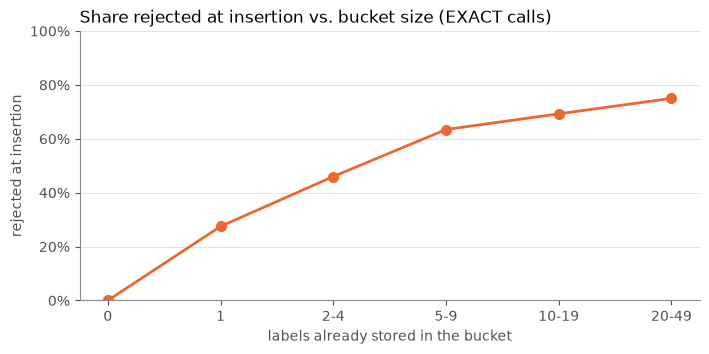

,n,rejected
bucket_bin,,
0,4729,0.000000
1,6166,0.274895
2-4,23511,0.459955
5-9,42437,0.634423
10-19,26166,0.692540
20-49,1432,0.750000


In [14]:
bins = [0, 1, 2, 5, 10, 20, 50, np.inf]
bin_names = ["0", "1", "2-4", "5-9", "10-19", "20-49", "50+"]
exact = labels[labels["level"] == "exact"].copy()
exact["bucket_bin"] = pd.cut(exact["bucket_stored"], bins=bins, labels=bin_names, right=False)
by_bin = exact.groupby("bucket_bin", observed=True).agg(
    n=("label_id", "size"), rejected=("outcome", lambda s: (s == 0).mean()))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(by_bin.index.astype(str), by_bin["rejected"], color=COLORS["rejected at insertion"],
        linewidth=2, marker="o", markersize=7)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_xlabel("labels already stored in the bucket")
ax.set_ylabel("rejected at insertion")
ax.set_title("Share rejected at insertion vs. bucket size (EXACT calls)", loc="left")
plt.show()

by_bin